In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras 

In [3]:
# data loading 
data = np.load('cifar-10-python.npz')

In [4]:
data

NpzFile 'cifar-10-python.npz' with keys: x_test, x_train, y_train, y_test

In [5]:
x_train , y_train = data['x_train'], data['y_train']

In [6]:
# contain 50k imagess with 32 pixel * 32 pixel and 3 color channel 
x_train.shape

(50000, 32, 32, 3)

In [7]:
# there are 50k labels correponing to 50k images 
y_train.shape

(50000,)

In [8]:
x_test , y_test = data['x_test'], data['y_test']

In [9]:
x_test.shape

(10000, 32, 32, 3)

In [10]:
y_test.shape

(10000,)

In [11]:
# normalization 
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [12]:
print(x_train.dtype)
print(x_train.min())
print(x_train.max())
print(x_train[0].shape)

float32
0.0
1.0
(32, 32, 3)


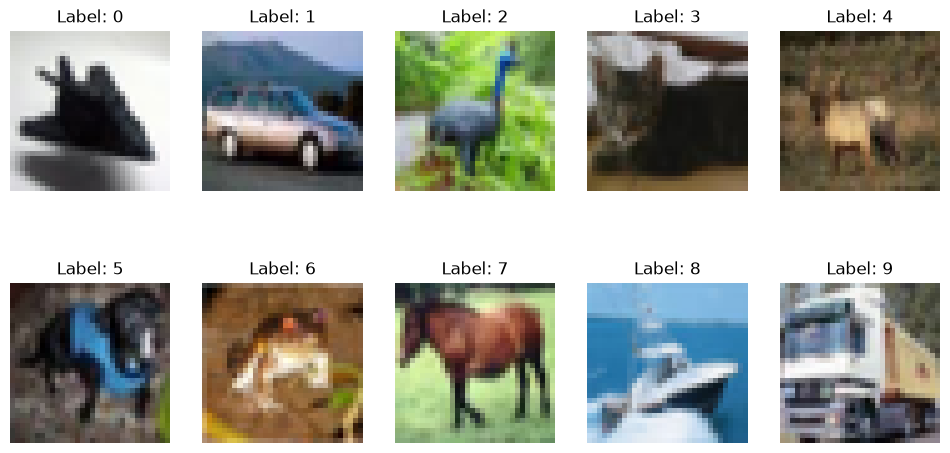

In [13]:
plt.figure(figsize=(12, 6))

for i in range(10):
    index = np.where(y_train.flatten() == i)[0][0]

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[index])
    plt.title(f"Label: {i}")
    plt.axis('off')

plt.show()

In [14]:
class_names = ["airplane" , "automobile" , "bird" , "cat" , "deer" , "dog" , "frog" , "horse" , "ship" , "truck"]  

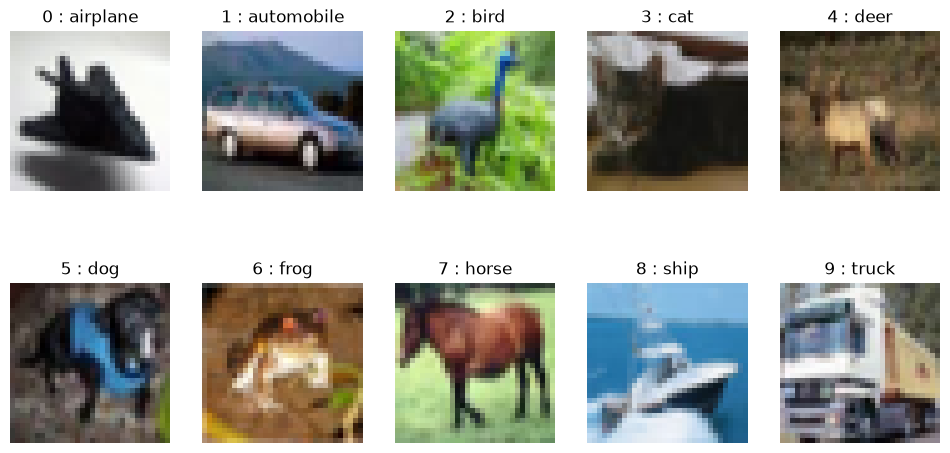

In [15]:
plt.figure(figsize=(12, 6))

for i in range(10):
    index = np.where(y_train.flatten() == i)[0][0]

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[index])
    plt.title(f"{i} : {class_names[i]}")
    plt.axis('off')

plt.show()

In [16]:
# architecture 
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    keras.layers.Flatten(),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │       1,573,376 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,738,890 (6.63 MB)

 Trainable params: 1,738,890 (6.63 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [18]:
es = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train , y_train,
    epochs = 20,
    batch_size = 32,
    validation_split = 0.2,
    callbacks=[es]
)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.3210 - loss: 1.8911 - val_accuracy: 0.3778 - val_loss: 1.7666
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.3921 - loss: 1.7032 - val_accuracy: 0.4119 - val_loss: 1.6554
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4227 - loss: 1.6153 - val_accuracy: 0.4297 - val_loss: 1.6083
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4457 - loss: 1.5558 - val_accuracy: 0.4271 - val_loss: 1.5981
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4632 - loss: 1.5068 - val_accuracy: 0.4583 - val_loss: 1.5330
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4784 - loss: 1.4671 - val_accuracy: 0.4607 - val_loss: 1.5209
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4922 - loss: 1.4306 - val_accuracy: 0.4684 - val_loss: 1.5187
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4996 - loss: 1.4018 - 

In [19]:
loss , acc = model.evaluate(x_test , y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5191 - loss: 1.3611


In [20]:
print(f"test accuracy : {acc * 100}")

test accuracy : 51.910001039505005


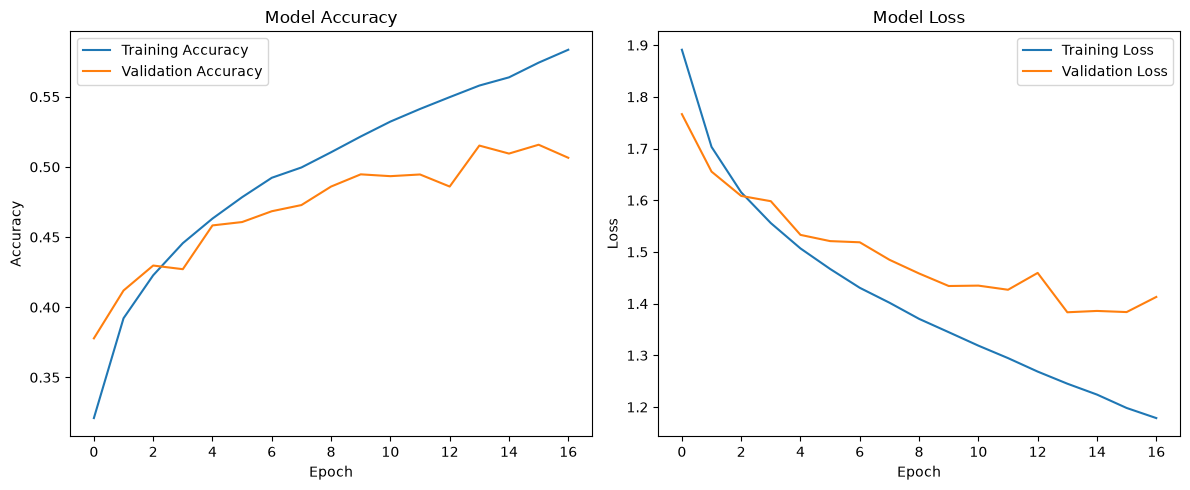

In [21]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [22]:
index = 23

prediction = model.predict(x_test[index:index+1])
predicted_class = np.argmax(prediction[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


Predicted class: truck
Actual class: truck


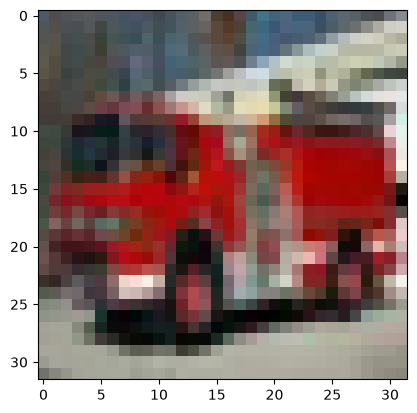

In [23]:
print("Predicted class:", class_names[predicted_class])
print("Actual class:", class_names[int(y_test[index])])
plt.imshow(x_test[index])